# Beyond Development: Explaining Climate Resilience Across Indian Districts — Review 2

**Research question.** Why do some economically developed Indian districts remain highly climate-vulnerable,
while some less-developed districts are resilient?

| Section | Content |
|---|---|
| 0 | Setup: Drive, repository, packages, tests |
| 1 | Data download: IMD 1991–2020 to Google Drive |
| 2 | Preprocessing + Table 1 + preprocessing error metrics |
| 3 | Big Data platform: Hadoop (HDFS + YARN), Hive, Spark |
| 4 | HDFS load, listing, Table 2 |
| 5 | MapReduce on YARN: local test, job, timings, correctness check |
| 6 | Hive: 30-year baseline + join, check against pandas |
| 7 | Spark k-means climate regimes + Table 3 |
| 8 | A-CPN (proposed model): architecture, parameters, Table 4 |
| 9 | Comparison models: Spark MLlib (LR, RF, GBT, Linear SVM) + MLP; A-CPN ablation |
| 10 | Table 5 (comparison, metrics, preprocessing before/after) and Table 6 (ablation, climate push) |
| 11 | Visualisations (only after every table) |
| 12 | Build the slides; appendix to show code |

**Fast path:** to show only the models, run section 0 and then sections 8–12; they use the committed
`data/processed/analysis_table.csv`. Single-node pseudo-distributed Hadoop (replication 1): no multi-machine
speed-up is claimed.

## 0. Setup

In [4]:
import os, subprocess, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/climate_project'      # Colab wipes its disk: persistent data lives on Drive
    REPO_DIR, IMD_DIR = f'{PROJECT}/repo', f'{PROJECT}/imd'
    os.makedirs(PROJECT, exist_ok=True)
    if not os.path.isdir(REPO_DIR):
        subprocess.run(['git', 'clone', 'https://github.com/deepankarkumar1310/hadoop-ml-algorithm-.git', REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    print(subprocess.run(['git', 'pull', '--ff-only'], capture_output=True, text=True).stdout.strip())
else:
    os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())
    IMD_DIR = 'data/imd'
START, END = 1991, 2020
os.environ.update(IMD_DIR=IMD_DIR, START=str(START), END=str(END))
print(os.getcwd())

Mounted at /content/drive
Already up to date.
/content/drive/MyDrive/climate_project/repo


In [5]:
!python3 -m pip -q install -r requirements.txt
!python3 -c "import torch, pyspark, imdlib; print('torch', torch.__version__, '| pyspark', pyspark.__version__)"
!python3 -m pytest tests -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.3/317.3 MB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 55.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.5/179.5 kB 12.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.
torch 2.11.0+cpu | pyspark 3.5.3
........................                                                 [100%]
24 passed in 26.80s


## 1. Dataset and IMD download

| Dataset | Source | Year | Format | Role |
|---|---|---|---|---|
| Climate Vulnerability Index + indicators (699 × 79) | NITI Aayog NDAP 7160 | 2021 | CSV | outcome + 2 development variables |
| Primary Census Abstract (640 districts) | Census of India | 2011 | CSV | 3 development variables (2011 baseline) |
| District boundaries (641 polygons) | DataMeet | 2011 | shapefile | grid → district weights |
| Daily gridded rainfall 0.25° | IMD Pune | 1991–2020 | binary .grd | hazard |
| Daily gridded Tmax / Tmin 1° | IMD Pune | 1991–2020 | binary .grd | hazard |

The IMD files (~848 MB) are downloaded to Google Drive and are never committed to GitHub.

In [6]:
!python3 scripts/download_imd.py --imd-dir "$IMD_DIR" --start $START --end $END


summary
  rain : 30/30 years, 763.3 MB
  tmax : 30/30 years, 42.1 MB
  tmin : 30/30 years, 42.1 MB


## 2. Preprocessing and preprocessing results

P1 Census rates · P2 NDAP↔Census matching · P3 development score and quadrants · P4 grid→district area weights ·
P5 district-day table (missing stays missing) · P6 Chennai orientation gate · P7 standardisation on training folds only.

In [7]:
!python3 scripts/census_vars.py | tail -8
!python3 scripts/match_districts.py | tail -8
!python3 scripts/build_integrated_table.py | tail -5
!python3 scripts/build_district_day.py --imd-dir "$IMD_DIR" --out-dir data/staging/district_day --start $START --end $END
# error check: our area-weighted aggregation vs the naive nearest-cell method
!python3 scripts/colab_checks.py --check aggregation --imd-dir "$IMD_DIR" --year $END

Data Not Available Jammu & Kashmir           0
range check:
      literacy_rate  female_literacy_rate  agri_worker_share
min           36.10                 30.29               0.00
mean          72.31                 63.74              56.74
max           97.91                 97.67              89.99
PROBLEMS: none
written -> data/processed/census2011_district_variables.csv
Punjab                3
Mizoram               3
Madhya Pradesh        2
Nagaland              1
Maharashtra           1
Haryana               1

written -> data/processed/ndap_census_district_crosswalk.csv
Karnataka         25
Jharkhand         24
Haryana           21

written -> data/processed/integrated_district_table.csv
  1991: 233,600 rows, 7.4 MB, missing rain 1460, tmax 16
  1992: 234,240 rows, 7.4 MB, missing rain 1464, tmax 404
  1993: 233,600 rows, 7.4 MB, missing rain 1460, tmax 513
  1994: 233,600 rows, 7.4 MB, missing rain 1460, tmax 442
  1995: 233,600 rows, 7.4 MB, missing rain 1460, tmax 106
  1996

In [8]:
# TABLE 1 + preprocessing error metrics (each step checked against a reference)
import json, pandas as pd
!python3 scripts/preprocessing_metrics.py > /dev/null
pm = json.load(open('results/preprocessing_metrics.json'))
ar = json.load(open('results/analysis_results.json'))
t1 = pd.DataFrame([
    ('Census 2011 districts', 640), ('Matched to NDAP', pm['matching']['matched']),
    ('With vulnerability index', ar['preprocessing']['with_index']),
    ('Complete (all 13 features)', pm['final_table']['rows']),
    ('Census population (official 1,210,854,977)', f"{pm['census']['population']:,}"),
    ('National literacy (official 72.98%)', f"{pm['census']['literacy_pct']:.4f}%"),
    ('Class balance High / Low', f"{pm['final_table']['class_high']} / {pm['final_table']['class_low']}"),
    ('NDAP columns >50% empty', f"{pm['ndap']['cols_over_half_empty']} of {pm['ndap']['cols']}"),
], columns=['Stage / check', 'Value'])
display(t1)
display(pd.DataFrame(pm['feature_signal_auc'].items(), columns=['feature', 'single-feature ROC-AUC']))
pm

,Stage / check,Value
0,Census 2011 districts,640
1,Matched to NDAP,602
2,With vulnerability index,589
3,Complete (all 13 features),469
4,"Census population (official 1,210,854,977)","1,210,854,977"
5,National literacy (official 72.98%),72.9819%
6,Class balance High / Low,237 / 232
7,NDAP columns >50% empty,64 of 79


,feature,single-feature ROC-AUC
0,agri_worker_share,0.674
1,female_literacy_rate,0.661
2,literacy_rate,0.660
3,tropical_nights,0.631
4,rx5day_mm,0.591
5,annual_rain_mm,0.583
6,heavy_rain_days,0.575
7,yield_variability,0.549
8,mgnrega_days,0.540
9,rain_variability,0.539


{'census': {'districts': 640,
  'population': 1210854977,
  'population_official': 1210854977,
  'population_abs_error': 0,
  'population_pct_error': 0.0,
  'literacy_pct': 72.9819,
  'literacy_official': 72.98,
  'literacy_abs_error_pp': 0.0019},
 'ndap': {'rows': 699,
  'cols': 79,
  'overall_missing_pct': 75.0,
  'cols_over_half_empty': 64},
 'matching': {'ndap_districts': 699,
  'match_types': {'exact': 528,
   'unmatched': 97,
   'alias': 45,
   'fuzzy': 23,
   'wordorder': 6},
  'matched': 602,
  'duplicate_censuscodes_after': 0},
 'grid_rain': {'pairs': 10291,
  'districts': 640,
  'max_abs_sum_error': 7.000000001866624e-08,
  'rmse_sum_error': 1.1930789996999434e-08},
 'grid_temp': {'pairs': 2074,
  'districts': 640,
  'max_abs_sum_error': 1.9999999989472883e-08,
  'rmse_sum_error': 4.5069390831050195e-09},
 'district_day': {'years': 30,
  'rows': 7013120,
  'rain_missing_pct': 0.625,
  'tmax_missing_pct': 0.3674541430918051,
  'tmin_missing_pct': 0.3649445610512867,
  'source'

## 3. Big Data platform

| Tool | Where | What it does | Why chosen |
|---|---|---|---|
| **HDFS** | `hadoop/setup_hadoop.sh`, `hadoop/load_hdfs.sh` | Stores raw, staging and processed zones | 128 MB blocks for parallel jobs; read directly by MapReduce, Hive, Spark |
| **YARN** | `hadoop/setup_hadoop.sh` | Allocates CPU/memory and runs MapReduce tasks | Hadoop's standard scheduler |
| **Hive** | `hive/setup_hive.sh`, `hive/project.hql` | SQL over HDFS: 30-year averages + join | Aggregation and joins are SQL tasks |
| **Spark** | `spark/setup_spark.sh`, `spark/*.py` | k-means climate regimes; MLlib baselines | In-memory, fast for iterative algorithms |

Java 8 for everything (Hive 3.1.3 fails on Java 11). Colab has no SSH, so every daemon is started directly.

In [9]:
def load_env(script):
    out = subprocess.run(['bash', '-c', f'source {script} > /tmp/setup.log 2>&1 && env'], capture_output=True, text=True)
    print(open('/tmp/setup.log').read()[-1500:])
    for line in out.stdout.splitlines():
        k, _, v = line.partition('=')
        if k in ('JAVA_HOME', 'HADOOP_HOME', 'HADOOP_CONF_DIR', 'PATH', 'HIVE_HOME', 'HADOOP_STREAMING_JAR',
                 'HDFS_NAMENODE_USER', 'HDFS_DATANODE_USER', 'YARN_RESOURCEMANAGER_USER', 'YARN_NODEMANAGER_USER',
                 'PYSPARK_PYTHON', 'SPARK_LOCAL_IP'):
            os.environ[k] = v

load_env('hadoop/setup_hadoop.sh')
!hadoop version | head -1
!jps
!hdfs dfsadmin -report | head -12

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Hadoop 3.3.6 running (single node, replication 1, 2 vcores, YARN 9731 MB)
15281 NodeManager
15188 ResourceManager
15033 NameNode
15118 DataNode

Hadoop 3.3.6
15281 NodeManager
15188 ResourceManager
15033 NameNode
15950 Jps
15118 DataNode
Configured Capacity: 115658190848 (107.72 GB)
Present Capacity: 89791307776 (83.62 GB)
DFS Remaining: 89791283200 (83.62 GB)
DFS Used: 24576 (24 KB)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0


## 4. HDFS load and Table 2

In [10]:
!bash hadoop/load_hdfs.sh "$IMD_DIR" data/staging/district_day
!hdfs dfs -put -f data/processed/analysis_table.csv /project/processed/
!hdfs dfs -ls /project /project/raw /project/raw/imd
!hdfs dfs -du -s -h /project/raw /project/staging /project/processed /project

HDFS usage by zone (measured):
9.8 M    9.8 M    /project/raw/boundaries
960.9 K  960.9 K  /project/raw/census
808.3 M  808.3 M  /project/raw/imd
244.1 K  244.1 K  /project/raw/ndap
728.0 M  728.0 M  /project/raw/imd/rain
40.2 M   40.2 M   /project/raw/imd/tmax
40.2 M   40.2 M   /project/raw/imd/tmin
212.5 M  212.5 M  /project/staging/district_day
1.0 G  1.0 G  /project
Found 3 items
drwxr-xr-x   - root supergroup          0 2026-10-22 04:53 /project/processed
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/raw
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/staging
Found 4 items
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/raw/boundaries
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/raw/census
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/raw/imd
drwxr-xr-x   - root supergroup          0 2026-10-22 04:51 /project/raw/ndap
Found 3 items
drwxr-xr-x   - root supergroup          0 20

## 5. MapReduce on YARN

**Map:** each district-day row → key (censuscode, year). **Reduce:** sort the days by date and compute 7 yearly
indices (rain total, heavy-rain days, max 5-day rain, longest dry spell, mean Tmax, hot days, tropical nights).
Incomplete years are left blank (never 0); malformed rows go to a Hadoop counter.

In [12]:
# local test of the same mapper/reducer
!head -2000 data/staging/district_day/district_day_${END}.csv | python3 mapreduce/mapper.py | sort | python3 mapreduce/reducer.py 2>/dev/null | head -3
!bash hadoop/run_mapreduce.sh /project/staging/district_day /project/processed/district_year 2 2>&1 | grep -E "Map input records|Reduce output records|bad_rows|completed successfully|ERROR"
!hdfs dfs -getmerge /project/processed/district_year data/processed/district_year_indices.csv
!wc -l data/processed/district_year_indices.csv

head: cannot open 'data/staging/district_day/district_day_020.csv' for reading: No such file or directory
2026-10-22 05:06:25,913 INFO mapreduce.Job: Job job_1792644666535_0002 completed successfully
		Map input records=7013120
		Reduce output records=19200
		IO_ERROR=0
19200 data/processed/district_year_indices.csv


In [13]:
# scalability: 1 / 10 / 30 years, 2 repeats each (single node)
!python3 scripts/time_mapreduce.py --years 1 10 30 --repeats 2
!cat results/scalability_timings.csv
# correctness check: the 7 MapReduce indices recomputed independently in pandas
!python3 scripts/colab_checks.py --check mapreduce

HDFS has 30 years: 1991-2020
    1 years  run 1: 234,240 records, 7.4 MB, 56.4 s
    1 years  run 2: 234,240 records, 7.4 MB, 52.8 s
   10 years  run 1: 2,337,920 records, 74.2 MB, 141.4 s
   10 years  run 2: 2,337,920 records, 74.2 MB, 138.6 s
   30 years  run 1: 7,013,120 records, 222.8 MB, 326.2 s
   30 years  run 2: 7,013,120 records, 222.8 MB, 339.4 s
results -> results/scalability_timings.csv
  figure -> figures/fig08_10_scalability.png
years,first_year,last_year,repeat,hdfs_input_bytes,map_input_records,reduce_output_records,runtime_s,records_per_s,reducers
1,2020,2020,1,7440219,234240,640,56.36,4156,2
1,2020,2020,2,7440219,234240,640,52.78,4438,2
10,2011,2020,1,74240814,2337920,6400,141.38,16537,2
10,2011,2020,2,74240814,2337920,6400,138.58,16871,2
30,1991,2020,1,222777905,7013120,19200,326.21,21499,2
30,1991,2020,2,222777905,7013120,19200,339.44,20661,2
{
  "area_vs_nearest_cell": {
    "year": 2020,
    "districts": 636,
    "rmse_mm": 286.9036266248581,
    "mae_mm": 151.726

## 6. Hive: 30-year baseline + join, checked against pandas

In [14]:
load_env('hive/setup_hive.sh')
!cd /opt/hive-metastore && hive --hivevar start=$START --hivevar end=$END -f $OLDPWD/hive/project.hql 2>/dev/null
!hdfs dfs -getmerge /project/hive/warehouse/project.db/integrated_district data/processed/integrated_district_hive.csv
!python3 scripts/build_climate_baseline.py --start $START --end $END
!python3 scripts/join_climate.py --check-hive data/processed/integrated_district_hive.csv
!cat results/hive_check.json

curl: (22) The requested URL returned error: 404
Hive 3.1.3 ready (embedded Derby metastore at /opt/hive-metastore)

_u1.stage	_u1.districts
matched and present in census	602
analysis set (complete cases)	469
districts with climate years	640
ndap rows matched to census	602
census districts	640
censuscode	annual_rain_mm	rain_variability	rx5day_mm	heavy_rain_days	max_dry_spell	mean_tmax	hot_days	tropical_nights	n_years_rain	n_years_temp
s.censuscode	s.district_name	s.state_name	s.climate_vul_in	s.literacy_rate	s.female_literacy_rate	s.agri_worker_share	s.mgnrega_days	s.yield_variability	s.z_literacy_rate	s.z_female_literacy_rate	s.z_agri_worker_share	s.z_mgnrega_days	s.z_yield_variability	s.development_score	s.dev_group	s.vul_group	s.quadrant	s.match_type	b.annual_rain_mm	b.rain_variability	b.rx5day_mm	b.heavy_rain_days	b.max_dry_spell	b.mean_tmax	b.hot_days	b.tropical_nights	b.n_years_rain	b.n_years_temp
quadrant	districts	rain_mm	rx5day	hot_days	dry_spell
High dev / High vul	92	1239.7	

## 7. Spark k-means climate regimes + Table 3

In [15]:
load_env('spark/setup_spark.sh')
!python3 spark/kmeans_regimes.py --input hdfs://localhost:9000/project/processed/analysis_table.csv --output hdfs://localhost:9000/project/processed/climate_regimes 2>&1 | grep -E "k=|chosen"
import pandas as pd, json
km = json.load(open('results/kmeans_regimes.json'))
t = pd.read_csv('results/scalability_timings.csv')
display(pd.DataFrame([
    ('MapReduce', f"{int(t.map_input_records.max()):,} district-day rows", f"{int(t.reduce_output_records.max()):,} district-years",
     f"{t[t.years == t.years.max()].runtime_s.mean():.0f} s"),
    ('Hive baseline + join', 'district-years + development table', '469-district table', 'checked against pandas'),
    ('Spark k-means', '8 hazard variables', f"{km['k']} climate regimes", f"silhouette {km['silhouette']:.3f}"),
], columns=['Job', 'Input', 'Output', 'Result']))

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/22 05:37:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Spark 3.5.3 OK, default parallelism 2

k=2 silhouette=0.651
k=3 silhouette=0.331
k=4 silhouette=0.392
k=5 silhouette=0.363
k=6 silhouette=0.458
k=7 silhouette=0.460
k=8 silhouette=0.465
chosen k=2 (silhouette 0.651); sizes {1: 374, 0: 95}


,Job,Input,Output,Result
0,MapReduce,"7,013,120 district-day rows","19,200 district-years",333 s
1,Hive baseline + join,district-years + development table,469-district table,checked against pandas
2,Spark k-means,8 hazard variables,2 climate regimes,silhouette 0.651


## 8. Proposed model: A-CPN (Attentive Climate Push Network)

`logit = development baseline (linear, 5 features) + climate push (attention → KAN → residual MLP, 8 hazard features)`.
MC Dropout gives the uncertainty of each district's push; split conformal prediction gives 90% prediction sets.
The vulnerability index is only the target, never an input.

In [16]:
import sys; sys.path.insert(0, '.')
from models.acpn import ACPN
net = ACPN()
print(net)
print('trainable parameters:', sum(p.numel() for p in net.parameters() if p.requires_grad))
# True = retrain every model here (~1 hour on 2 vCPU, mostly the Spark baselines);
# False = show the committed results in results/ (produced by the same scripts)
RERUN_MODELS = True
if RERUN_MODELS:
    !python3 scripts/train_acpn.py
print(open('results/table4_model_card.json').read())

ACPN(
  (dev): Linear(in_features=5, out_features=1, bias=True)
  (att): FeatureAttention(
    (net): Sequential(
      (0): Linear(in_features=8, out_features=16, bias=True)
      (1): Tanh()
      (2): Linear(in_features=16, out_features=8, bias=True)
    )
  )
  (climate): Sequential(
    (0): KANLayer(
      (base): Linear(in_features=8, out_features=16, bias=True)
    )
    (1): Dropout(p=0.3, inplace=False)
    (2): ResidualBlock(
      (body): Sequential(
        (0): Linear(in_features=16, out_features=16, bias=True)
        (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Dropout(p=0.3, inplace=False)
      )
    )
    (3): Linear(in_features=16, out_features=1, bias=False)
  )
)
trainable parameters: 1775
{
  "parameters": 1775,
  "train_time": "2.0 s per fold",
  "train_time_full_s": 2.79,
  "epochs_full": 64,
  "predict_ms_per_district": 0.0237,
  "hardware": "x86_64 CPU, torch 2.11.0+cpu",
  "conformal_ta

## 9. Comparison models: Spark MLlib (LR, RF, GBT, Linear SVM) and a standard MLP

In [17]:
if RERUN_MODELS:
    !python3 spark/train_baselines.py 2>&1 | grep -E "folds done|districts read"
    !python3 scripts/train_mlp.py
    !python3 scripts/train_acpn.py --raw        # effect of preprocessing on the models (raw vs preprocessed features)
    !python3 scripts/train_acpn.py --ablation

MLP scaled done
MLP raw done
raw A-CPN done
ablation: Without feature attention
ablation: Without KAN layer (plain MLP)
ablation: Without residual block
ablation: Climate only (no development baseline)
ablation: Development only (no climate push)
ablation: Linear climate part (no deep layers)


## 10. Tables 5 and 6

In [18]:
!python3 scripts/evaluate.py > /dev/null
t5 = pd.read_csv('results/table5_comparison.csv')
print('TABLE 5 - comparison (mean over 25 folds; LOSO = leave-one-state-out)')
display(t5[['model', 'tool', 'roc_auc', 'roc_auc_sd', 'bal_acc', 'accuracy', 'f1', 'loso_auc', 'train_time']].round(3))
print('Detailed metrics'); display(pd.read_csv('results/classifier_metrics_full.csv').round(3))
print('Confusion matrices (summed over 25 folds)'); display(pd.read_csv('results/confusion_matrices.csv'))
print('95% CI and corrected paired t-test vs A-CPN'); display(pd.read_csv('results/significance.csv').round(4))
print('TABLE 6a - ablation'); display(pd.read_csv('results/table6_ablation.csv').round(3))
print('Preprocessing before vs after (raw vs preprocessed features)'); display(pd.read_csv('results/preprocessing_before_after.csv').round(3))
print('TABLE 6b - climate push'); print(open('results/table6_climate_push.json').read()[:3000])

TABLE 5 - comparison (mean over 25 folds; LOSO = leave-one-state-out)


,model,tool,roc_auc,roc_auc_sd,bal_acc,accuracy,f1,loso_auc,train_time
0,A-CPN (proposed),Novel DL · PyTorch,0.760,0.045,0.701,0.701,0.693,0.694,2.020
1,Logistic Regression,Spark MLlib,0.747,0.042,0.691,0.692,0.701,0.661,1.673
2,Random Forest,Spark MLlib,0.804,0.036,0.715,0.715,0.708,0.706,1.469
3,Gradient-Boosted Trees,Spark MLlib,0.811,0.034,0.726,0.725,0.724,0.698,13.384
4,Linear SVM,Spark MLlib,0.755,0.039,0.696,0.696,0.708,0.691,10.403
5,Standard MLP,PyTorch,0.784,0.037,0.699,0.699,0.692,0.710,1.223


Detailed metrics


,model,precision,precision_sd,recall,recall_sd,specificity,specificity_sd,mcc,mcc_sd,kappa,...,log_loss,log_loss_sd,brier,brier_sd,ece,ece_sd,macro_f1,macro_f1_sd,predict_time,predict_time_sd
0,A-CPN (proposed),0.720,0.048,0.673,0.074,0.729,0.068,0.405,0.081,0.402,...,0.614,0.054,0.204,0.019,0.120,0.027,0.699,0.043,0.000,0.000
1,Logistic Regression,0.688,0.043,0.718,0.071,0.665,0.066,0.386,0.086,0.383,...,0.611,0.046,0.206,0.014,0.101,0.025,0.691,0.042,0.002,0.001
2,Random Forest,0.735,0.050,0.689,0.077,0.742,0.074,0.434,0.078,0.430,...,0.539,0.031,0.182,0.014,0.095,0.022,0.714,0.040,0.002,0.000
3,Gradient-Boosted Trees,0.736,0.046,0.718,0.077,0.733,0.066,0.454,0.071,0.451,...,0.570,0.070,0.188,0.022,0.131,0.029,0.724,0.036,0.002,0.000
4,Linear SVM,0.689,0.038,0.733,0.074,0.659,0.062,0.396,0.072,0.392,...,NaN,NaN,NaN,NaN,NaN,NaN,0.695,0.034,0.001,0.000
5,Standard MLP,0.719,0.057,0.674,0.089,0.724,0.086,0.404,0.088,0.398,...,0.579,0.052,0.194,0.019,0.114,0.031,0.697,0.044,0.000,0.000


Confusion matrices (summed over 25 folds)


...

TABLE 6a - ablation


,model,roc_auc,roc_auc_sd,f1,delta,p_value
0,Full A-CPN,0.760,0.045,0.693,0.000,NaN
1,Without feature attention,0.774,0.046,0.701,0.013,0.698
2,Without KAN layer (plain MLP),0.784,0.052,0.708,0.023,0.529
3,Without residual block,0.756,0.047,0.698,-0.005,0.902
4,Climate only (no development baseline),0.757,0.039,0.689,-0.004,0.910
5,Development only (no climate push),0.670,0.065,0.664,-0.090,0.068
6,Linear climate part (no deep layers),0.733,0.058,0.702,-0.028,0.495


Preprocessing before vs after (raw vs preprocessed features)


,model,auc_before,auc_after,f1_before,f1_after,acc_before,acc_after,auc_gain,f1_gain
0,A-CPN (proposed),0.737,0.760,0.672,0.693,0.679,0.701,0.023,0.021
1,Logistic Regression,0.747,0.747,0.701,0.701,0.692,0.692,0.000,0.000
2,Random Forest,0.805,0.804,0.708,0.708,0.715,0.715,-0.000,0.000
3,Gradient-Boosted Trees,0.811,0.811,0.724,0.724,0.726,0.725,-0.000,-0.000
4,Linear SVM,0.755,0.755,0.708,0.708,0.696,0.696,0.000,0.000
5,Standard MLP,0.759,0.784,0.678,0.692,0.711,0.699,0.025,0.013


TABLE 6b - climate push
{
  "by_quadrant": {
    "High dev / High vul": {
      "n": 92,
      "push": 0.3166866882143478,
      "push_sd": 1.3415773338593746,
      "share_positive": 0.5434782608695652,
      "factor": "max dry spell"
    },
    "High dev / Low vul": {
      "n": 143,
      "push": -0.532524995675063,
      "push_sd": 1.1708611301071816,
      "share_positive": 0.26573426573426573,
      "factor": "max dry spell"
    },
    "Low dev / High vul": {
      "n": 145,
      "push": 0.8122562042193103,
      "push_sd": 1.4286577258649953,
      "share_positive": 0.7241379310344828,
      "factor": "hot days"
    },
    "Low dev / Low vul": {
      "n": 89,
      "push": -0.9926610377943819,
      "push_sd": 1.3753455822038583,
      "share_positive": 0.19101123595505617,
      "factor": "annual rain mm"
    }
  },
  "by_regime": {
    "0": {
      "n": 95,
      "push": -0.9876338008294738,
      "factor": "max dry spell"
    },
    "1": {
      "n": 374,
      "push": 0.20

## 11. Visualisations (only after every table)

In [19]:
!python3 scripts/make_figures.py > /dev/null
from IPython.display import Image, display
def show(*names):
    for f in names:
        print(f); display(Image(f'figures/{f}.png'))

### 11a. Preprocessing figures

prep_quality_before_after


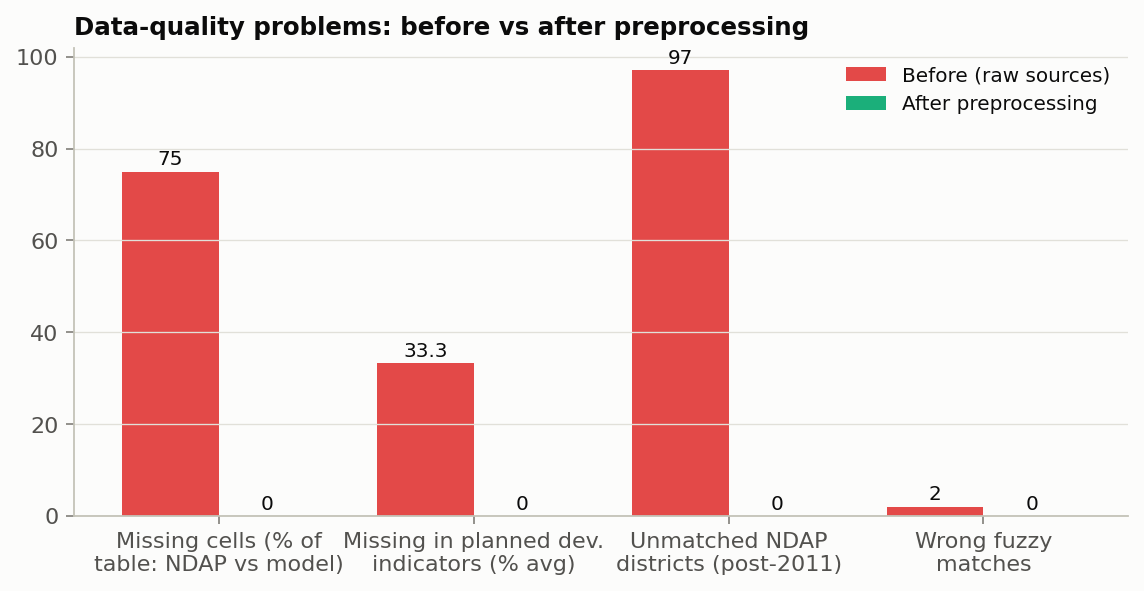

prep_feature_scaling


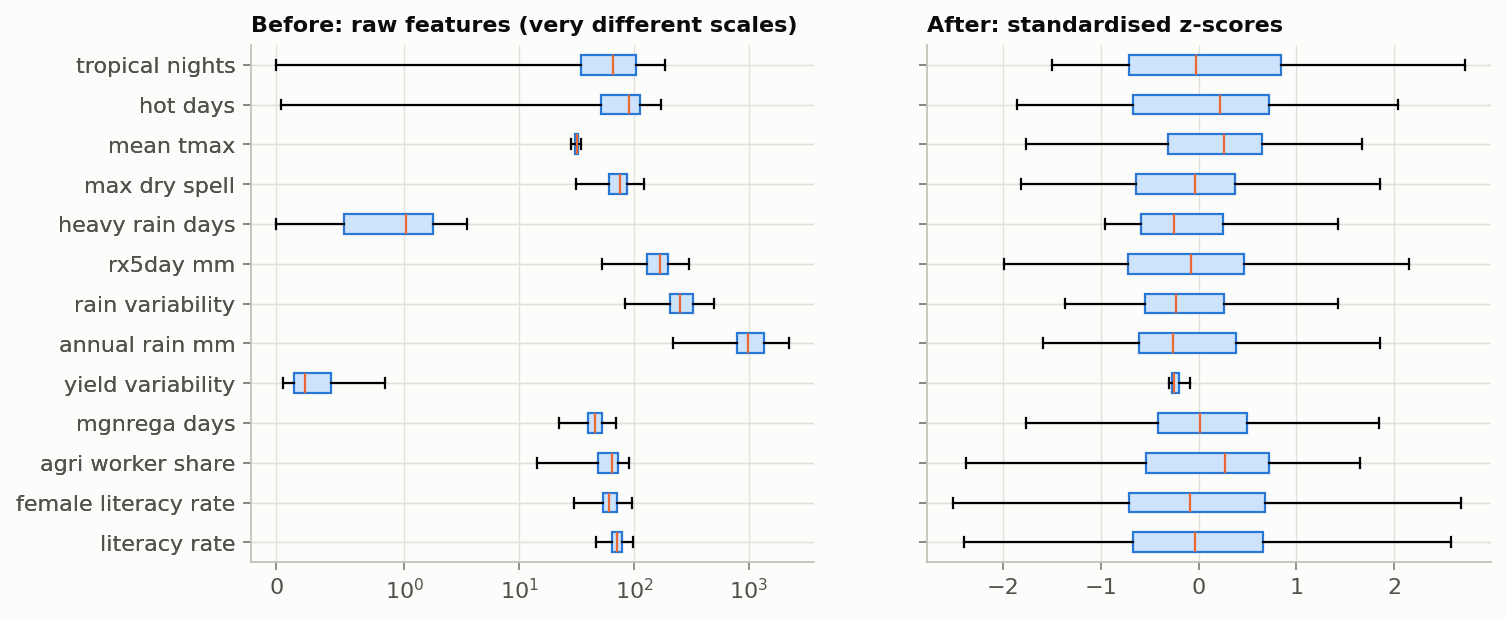

prep_retention


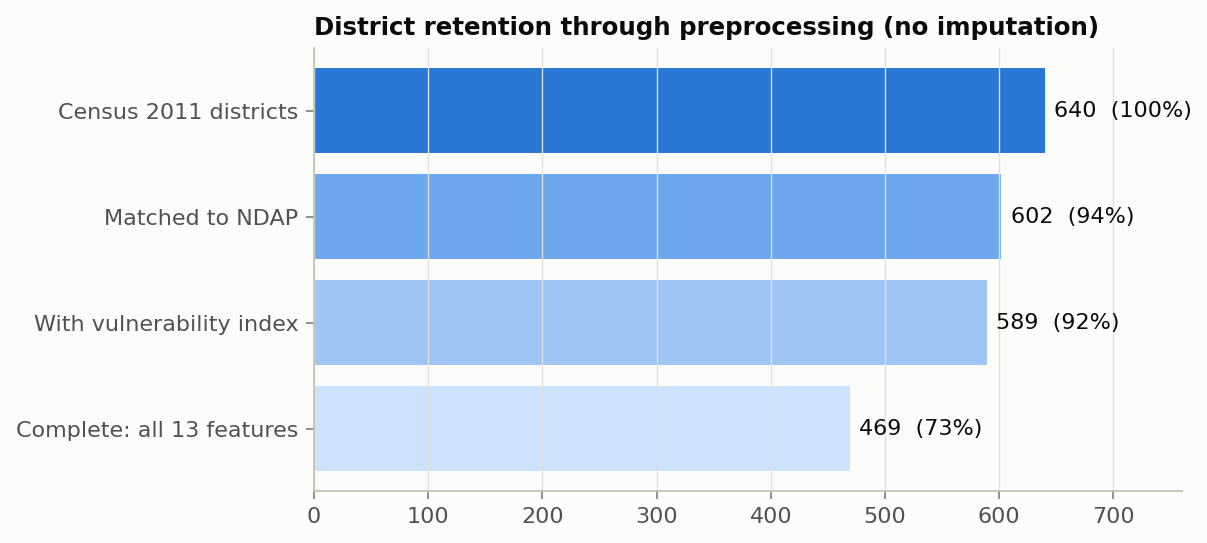

prep_feature_signal


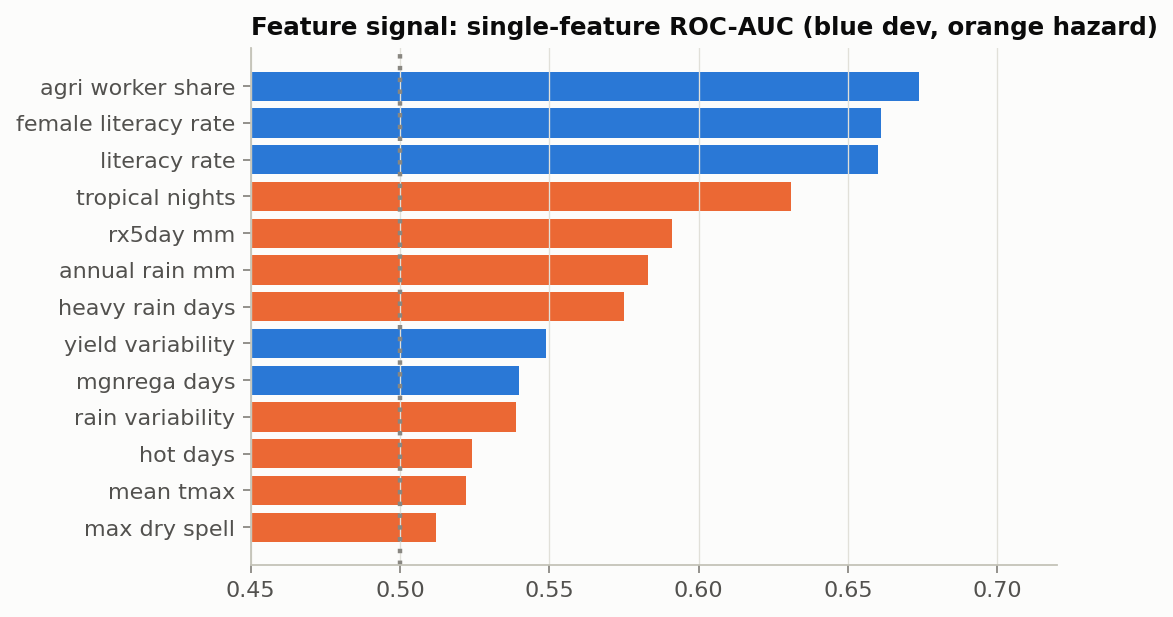

prep_correlation


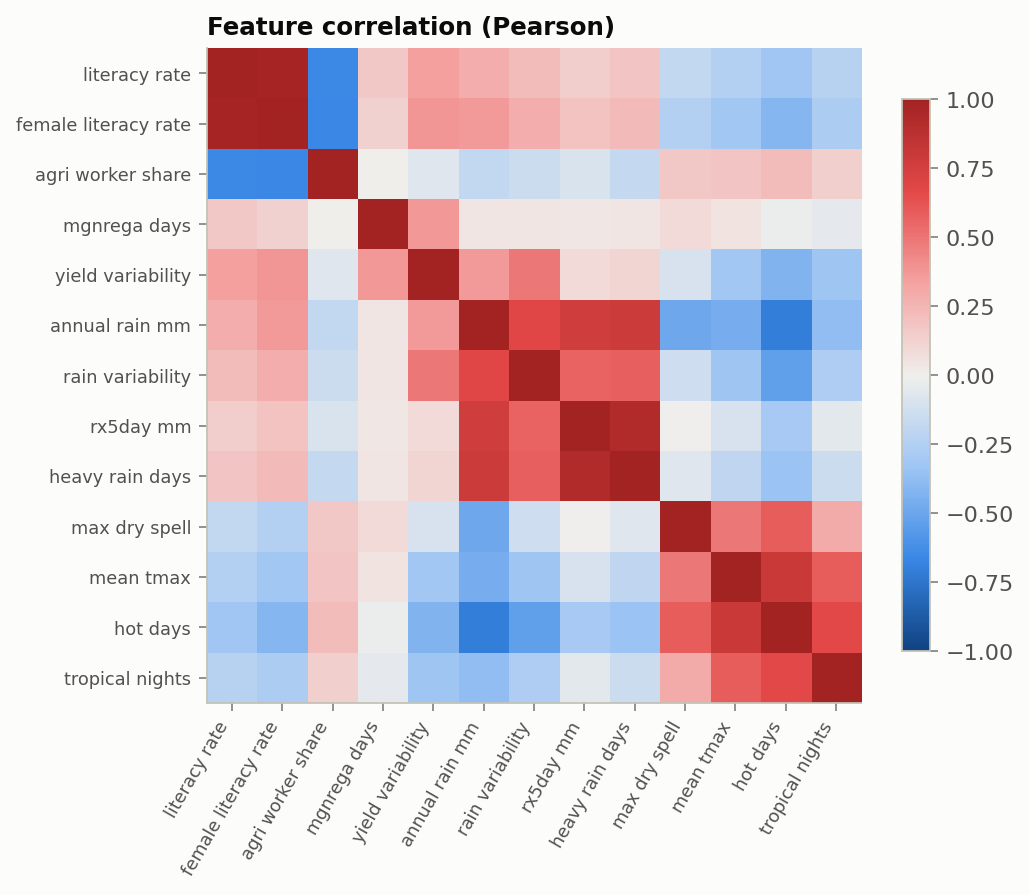

In [20]:
show('prep_quality_before_after', 'prep_feature_scaling', 'prep_retention', 'prep_feature_signal', 'prep_correlation')

### 11b. HDFS storage

hdfs_storage


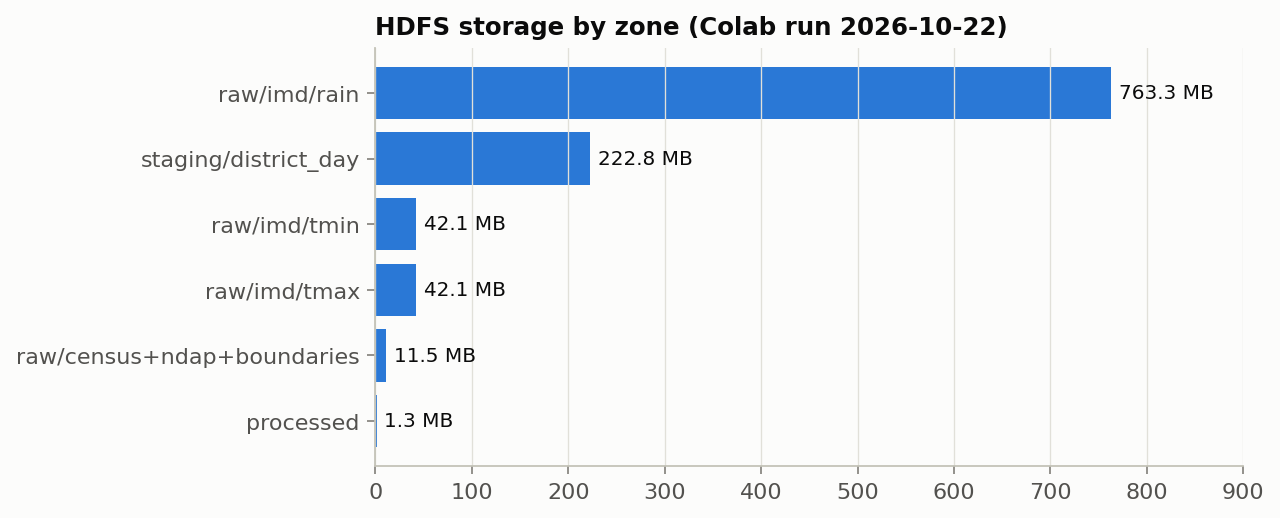

In [21]:
show('hdfs_storage')

### 11c. MapReduce and Spark k-means

mapreduce_scalability


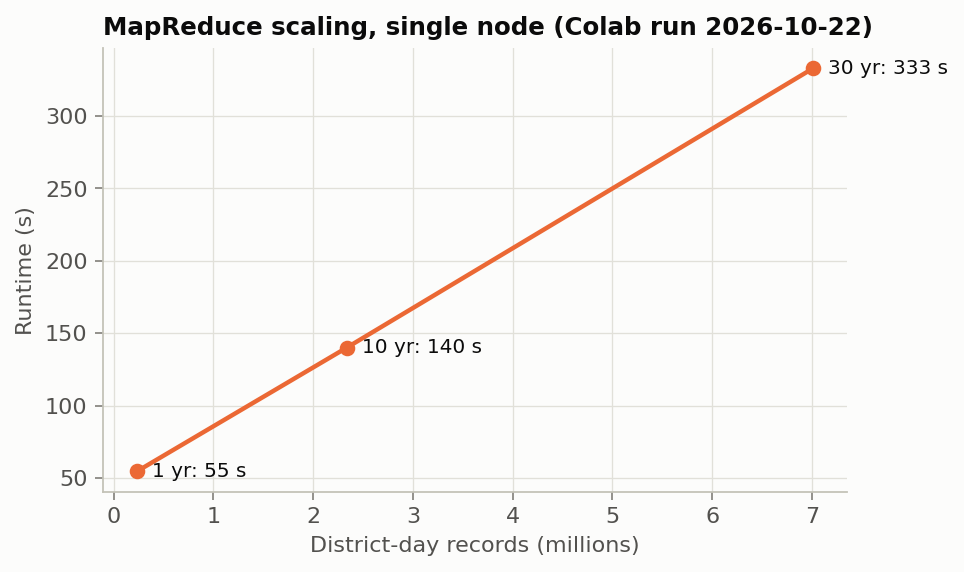

kmeans_silhouette


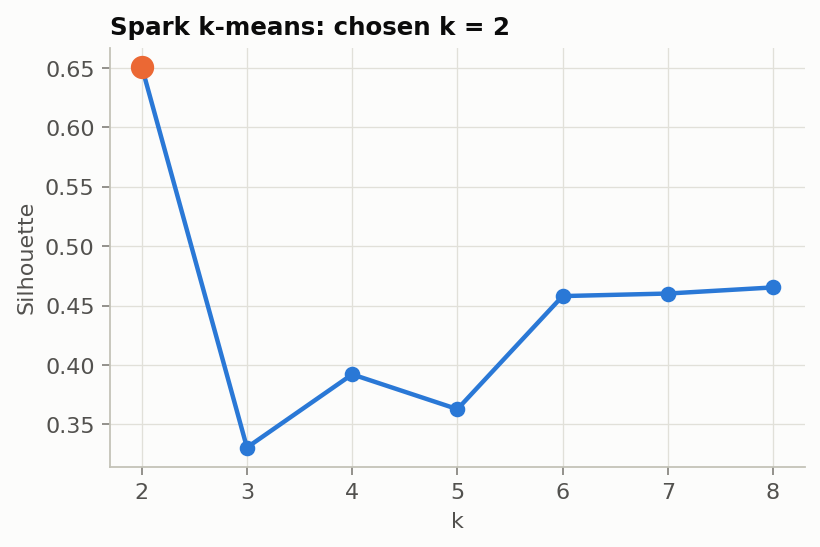

In [22]:
show('mapreduce_scalability', 'kmeans_silhouette')

### 11d. Models

roc_curves


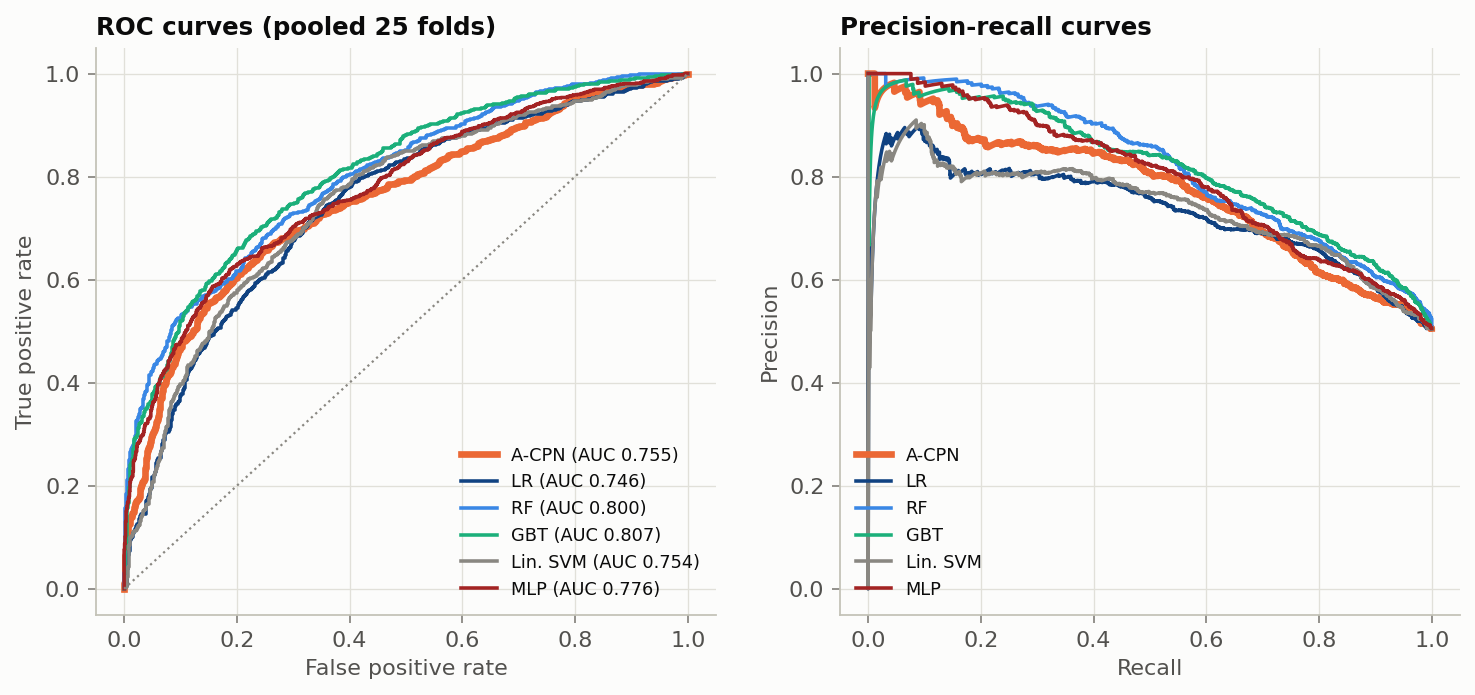

comparison_bars


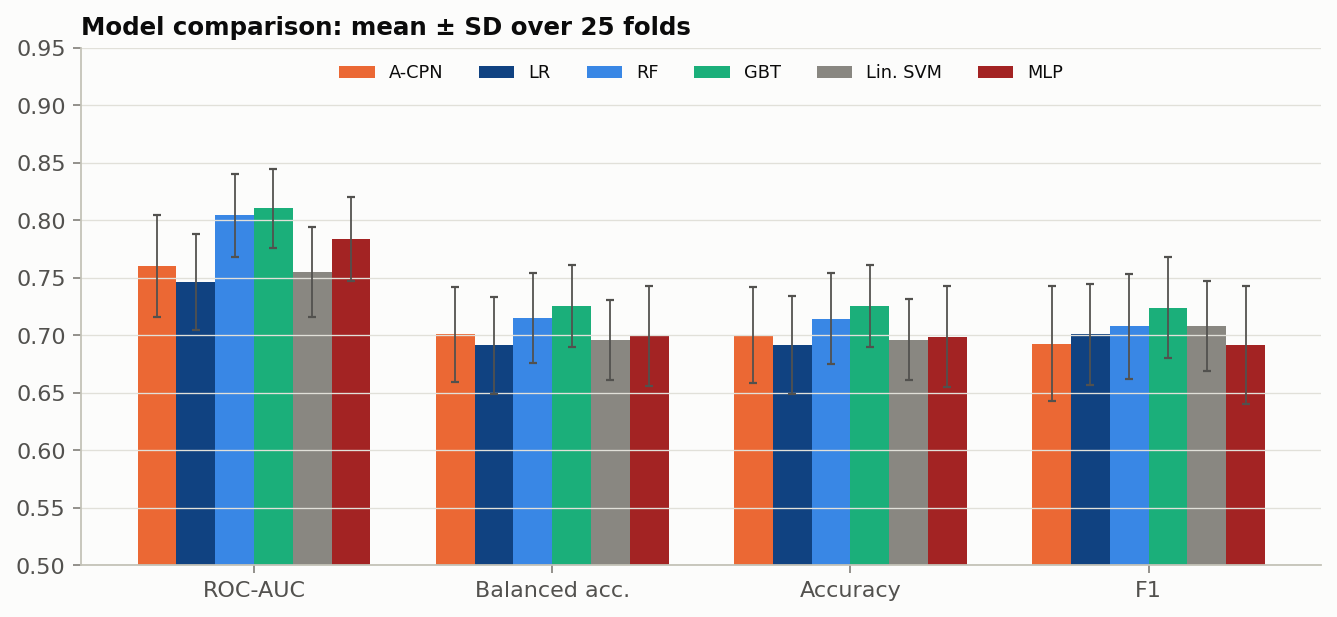

fold_boxplots


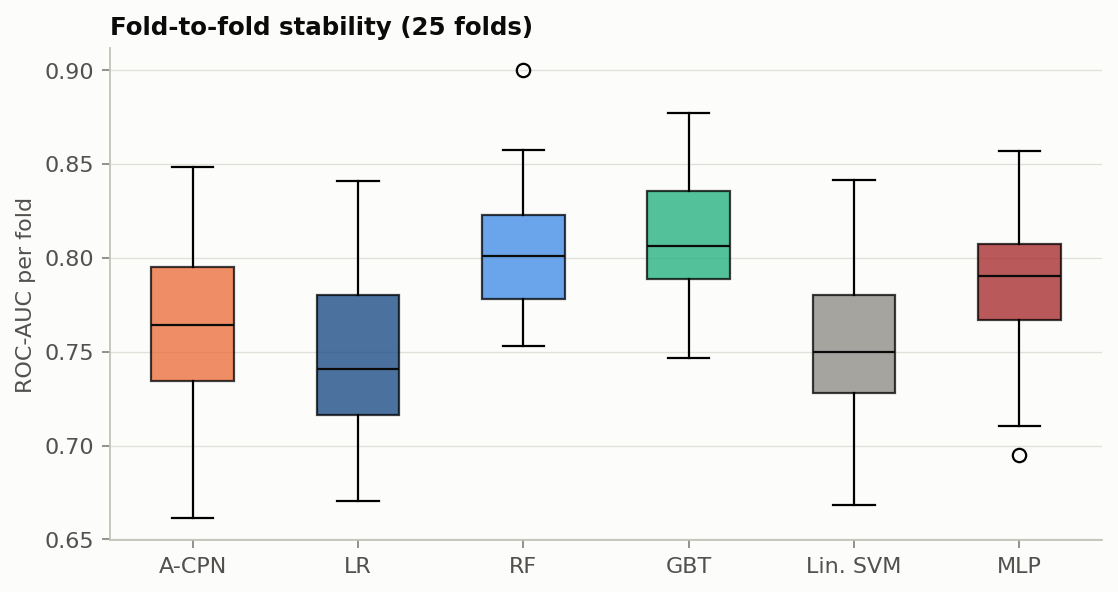

confusion_matrices


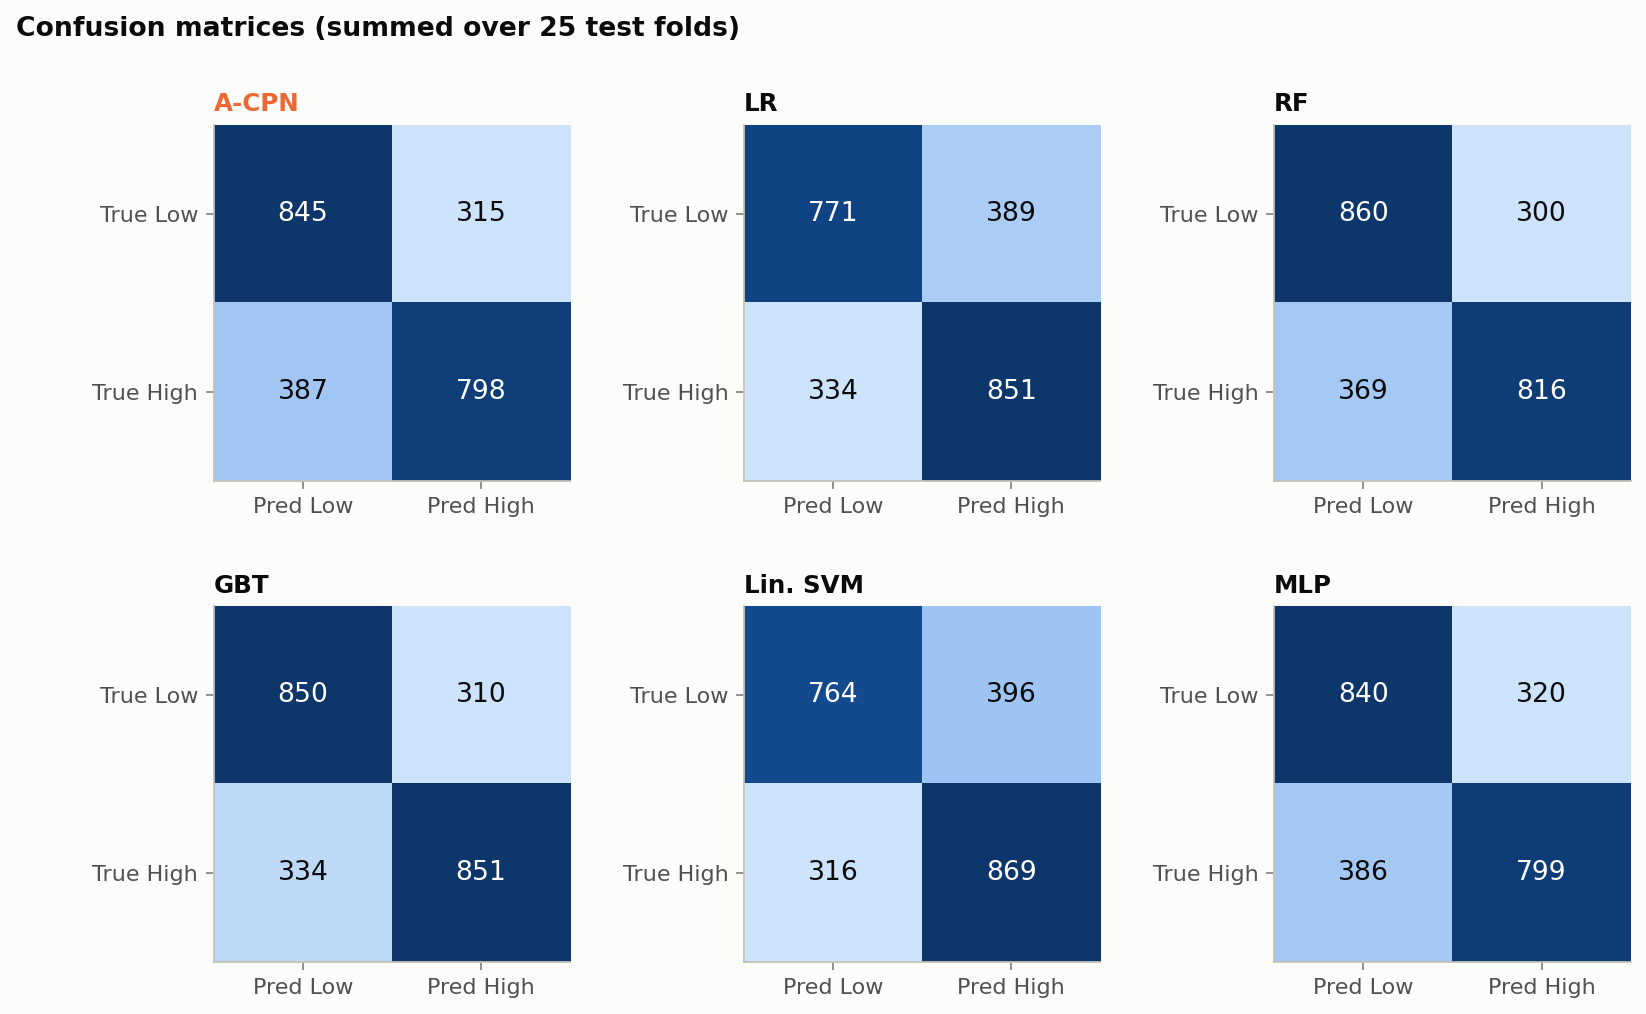

calibration


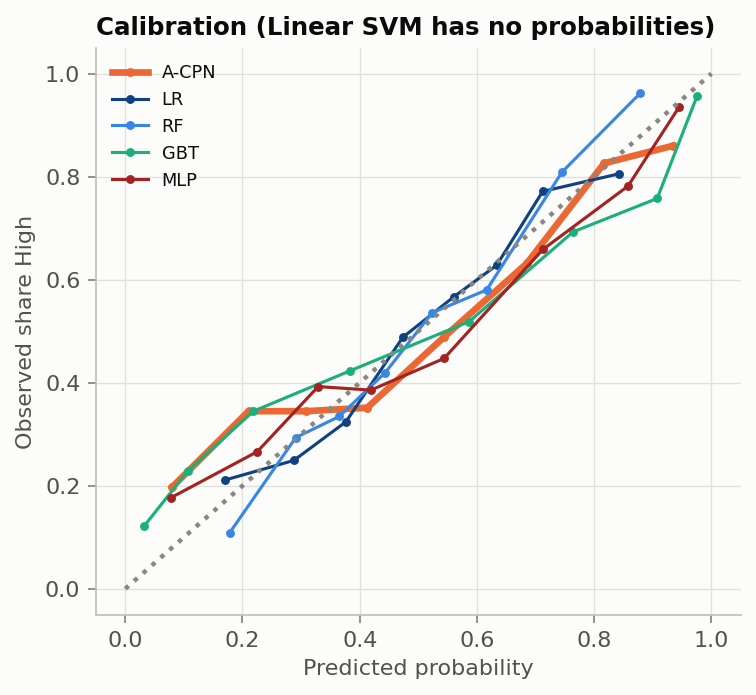

loso_by_state


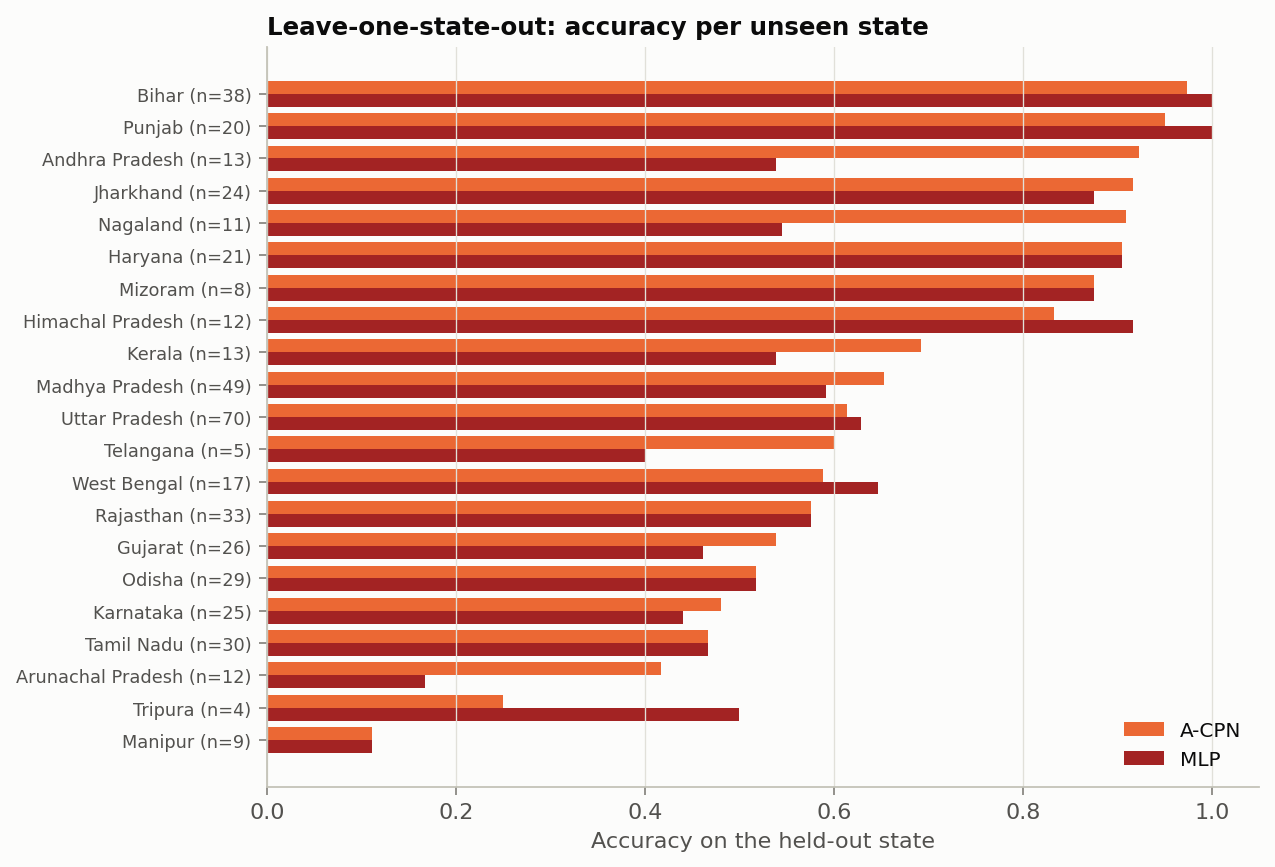

acpn_training_curve


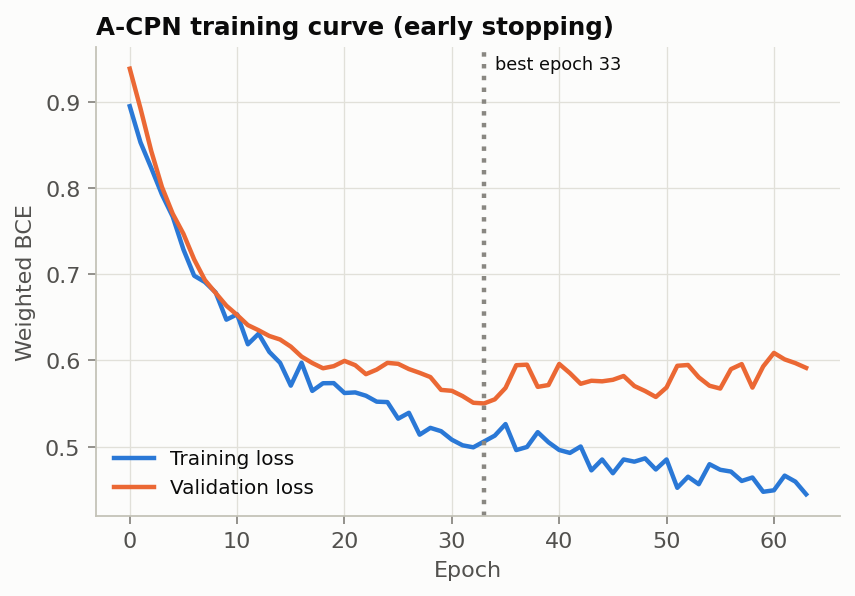

prep_model_gain


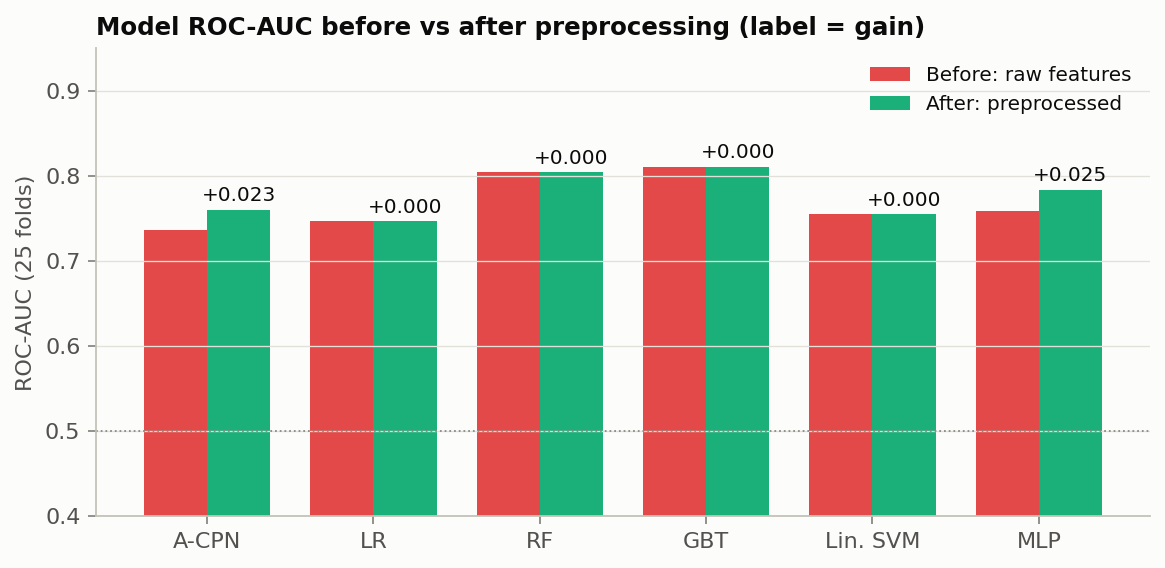

ablation


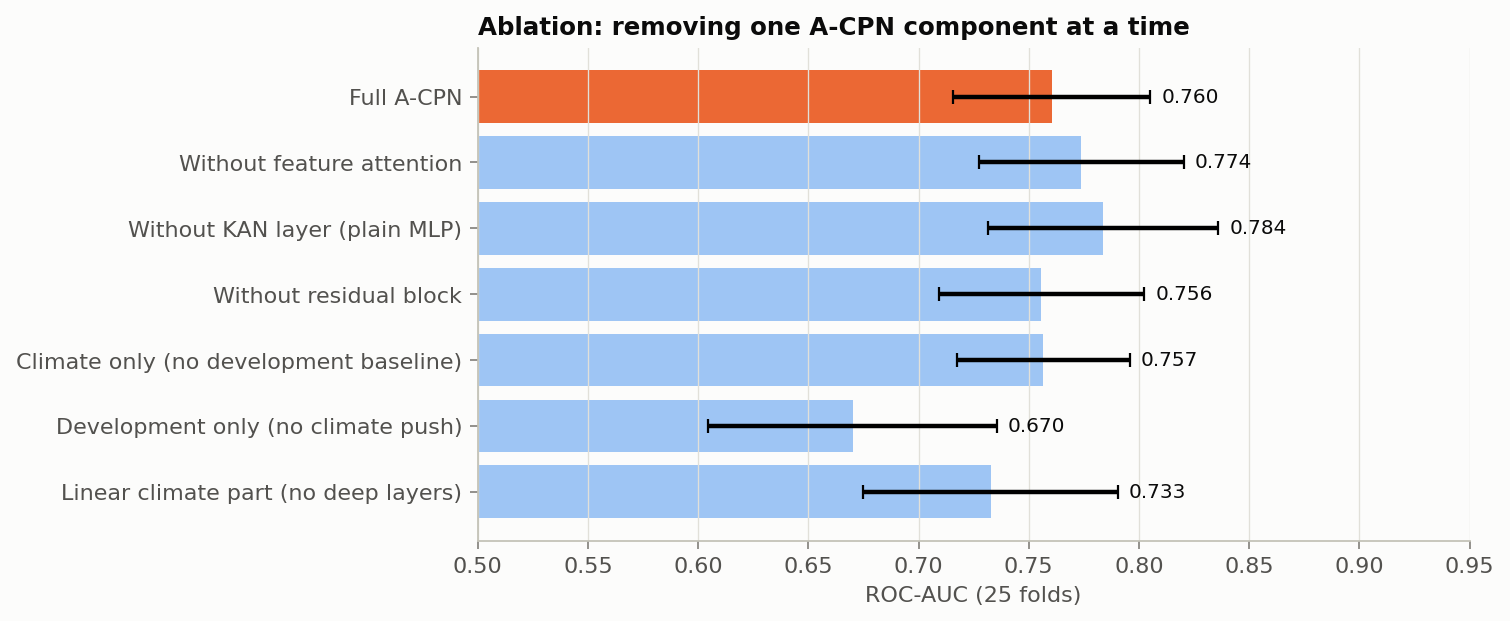

attention_importance


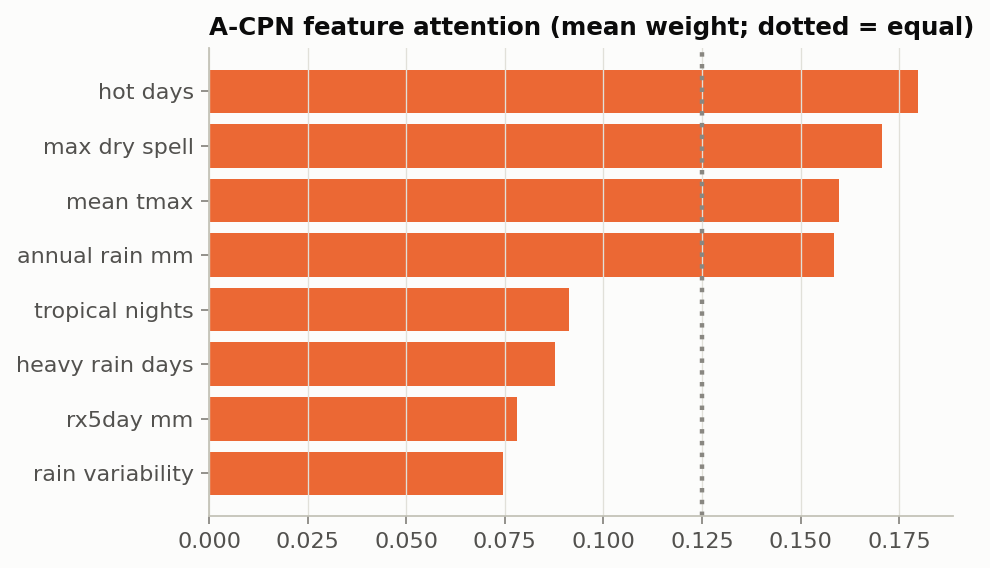

climate_push_by_quadrant


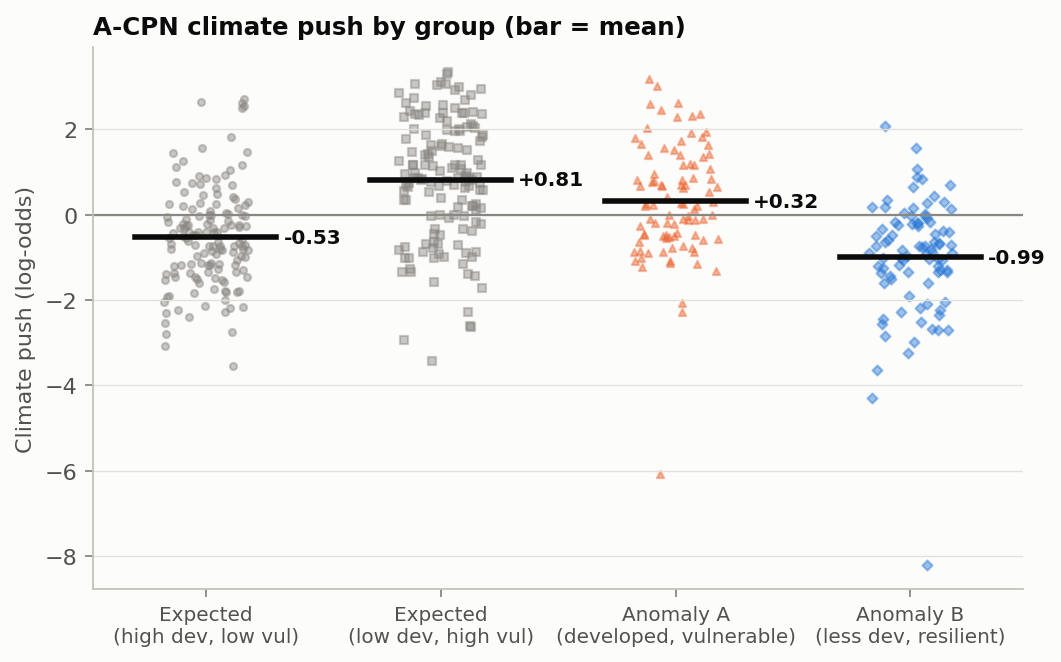

climate_push_map


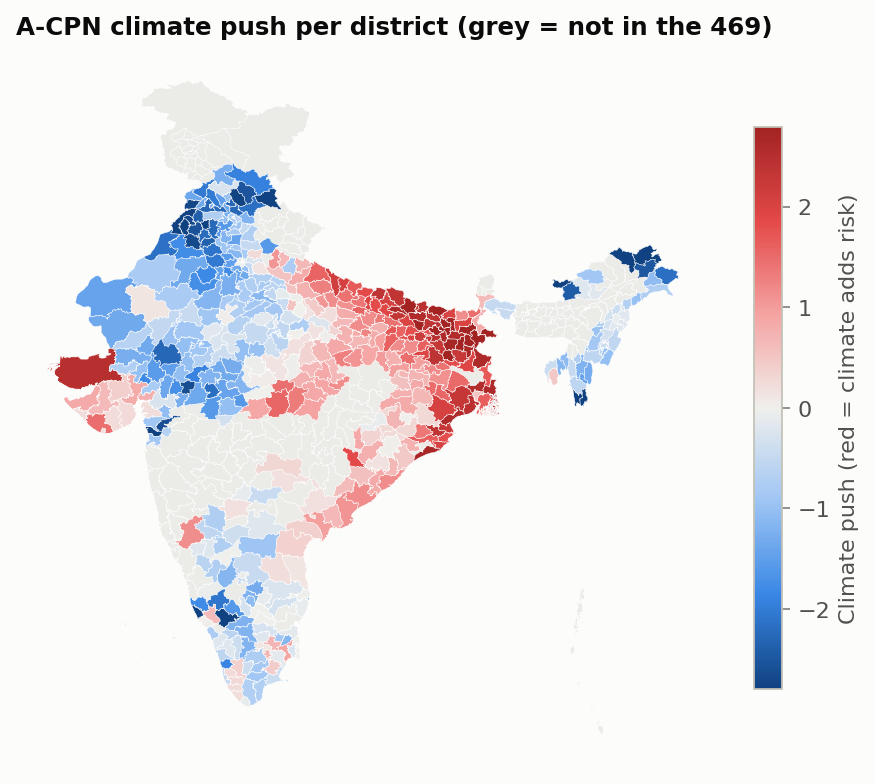

In [23]:
show('roc_curves', 'comparison_bars', 'fold_boxplots', 'confusion_matrices', 'calibration', 'loso_by_state', 'acpn_training_curve', 'prep_model_gain', 'ablation', 'attention_importance', 'climate_push_by_quadrant', 'climate_push_map')

## 12. Slides and appendix

In [24]:
!python3 scripts/build_deck.py

saved /content/drive/MyDrive/climate_project/repo/docs/Review2_Deck.pptx with 33 slides


In [25]:
# appendix: show any source file during the review
!cat mapreduce/mapper.py mapreduce/reducer.py
!cat hive/project.hql
!cat models/acpn.py

#!/usr/bin/env python3
"""Hadoop Streaming mapper: district-day records -> (district, year) groups.

Input  (one line per district per day, CSV, header optional)
    censuscode,date,rain_mm,tmax_c,tmin_c
    e.g. 603,1991-10-14,12.37,31.20,24.05
    A missing value is an empty field, never zero.

Output (key TAB value)
    censuscode,year <TAB> date,rain_mm,tmax_c,tmin_c

Malformed lines are counted in the Hadoop counter Project:bad_rows and
dropped; they are never repaired or guessed.
"""
import sys


def counter(name, n=1):
    sys.stderr.write(f"reporter:counter:Project,{name},{n}\n")


def main():
    for line in sys.stdin:
        line = line.strip()
        if not line or line.startswith("censuscode"):
            continue
        parts = line.split(",")
        if len(parts) != 5:
            counter("bad_rows")
            continue
        code, date, rain, tmax, tmin = parts
        if not code.isdigit() or len(date) != 10 or date[4] != "-":
            counter("bad_rows")
   